# Класифікація стилів живопису (WikiArt)

Задача: класифікація картин за 27 стилями на основі видобутих вручну візуальних ознак (WikiArt, ~81 тис. картин).
Випадкове вгадування: ~3.7%.

Ознаки (всього 651):
- Колір: 3D HSV гістограма (512)
- Лінії та форма: HOG (128)
- Текстура полотна/фарби: LBP (10)
- Контурна щільність: Canny (1)

Розбивка: 70% train, 15% val, 15% test зі стратифікацією.

In [ ]:
import os
import time
import tempfile
import tracemalloc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    top_k_accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Завантаження даних
csv_path = 'wikiart_features_all_styles.csv'
if not os.path.exists(csv_path):
    csv_path = 'wikiart_features.csv'

print(f'Завантаження {csv_path}...')
df = pd.read_csv(csv_path).dropna()
print(f'Завантажено {len(df)} картин. Кількість ознак: {df.shape[1] - 1}')

X = df.drop(columns=['label']).values
y_raw = df['label'].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
classes = label_encoder.classes_

# Стратифікований спліт (70% Train / 15% Val / 15% Test)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
val_ratio = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=val_ratio, random_state=42, stratify=y_train_val
)

print(f'Train: {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)')
print(f'Val:   {len(X_val)} ({len(X_val)/len(df)*100:.1f}%)')
print(f'Test:  {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)')
print(f'Кількість стилів: {len(classes)}')


Завантаження wikiart_features_all_styles.csv...
Завантажено 81444 картин. Кількість ознак: 651
Train: 57010 (70.0%)
Val:   12217 (15.0%)
Test:  12217 (15.0%)
Кількість стилів: 27


## Ваги класів

Кількість робіт у різних стилях суттєво відрізняється.
Звичайний `balanced` дає рідкісним стилям надто велику вагу, через що падає загальна точність.
Тому використовуємо згладжені ваги через корінь: $w_c \propto \frac{1}{\sqrt{N_c}}$.

In [ ]:
class_counts = np.bincount(y_train, minlength=len(classes))

balanced_weights = len(y_train) / (len(classes) * class_counts)

sqrt_weights = 1.0 / np.sqrt(class_counts)
sqrt_weights = sqrt_weights / np.mean(sqrt_weights)

sample_weight_train_balanced = balanced_weights[y_train]
sample_weight_train_smooth = sqrt_weights[y_train]

max_cls = np.argmax(class_counts)
min_cls = np.argmin(class_counts)
print('Порівняння ваг для найбільшого та найменшого класу:')
print(f'  {classes[max_cls]}: N={class_counts[max_cls]} | balanced={balanced_weights[max_cls]:.3f} | smoothed={sqrt_weights[max_cls]:.3f}')
print(f'  {classes[min_cls]}: N={class_counts[min_cls]} | balanced={balanced_weights[min_cls]:.3f} | smoothed={sqrt_weights[min_cls]:.3f}')


Порівняння ваг для найбільшого та найменшого класу:
  Impressionism: N=9142 | balanced=0.231 | smoothed=0.283
  Action_painting: N=68 | balanced=31.051 | smoothed=3.277


## Нормалізація ознак

1. Глобальна нормалізація + PCA до 128 компонент (для лінійних моделей).
2. Блочна нормалізація (L2 для HOG, корінь + L2 для гістограм HSV та LBP, MinMaxScaler для Canny).

In [16]:
# 1. Глобальна нормалізація + PCA (128)
X_tr_glob = normalize(np.sqrt(np.maximum(X_train, 0)), norm='l2')
X_va_glob = normalize(np.sqrt(np.maximum(X_val, 0)), norm='l2')
X_te_glob = normalize(np.sqrt(np.maximum(X_test, 0)), norm='l2')

pca = PCA(n_components=128, random_state=42)
X_tr_pca = pca.fit_transform(X_tr_glob)
X_va_pca = pca.transform(X_va_glob)
X_te_pca = pca.transform(X_te_glob)
print(f'PCA(128): пояснена дисперсія Train = {np.sum(pca.explained_variance_ratio_) * 100:.2f}%')

# 2. Блочна нормалізація (всі 651 ознаки)
c_tr = normalize(np.sqrt(np.maximum(X_train[:, :512], 0)), norm='l2')
c_va = normalize(np.sqrt(np.maximum(X_val[:, :512], 0)), norm='l2')
c_te = normalize(np.sqrt(np.maximum(X_test[:, :512], 0)), norm='l2')

h_tr = normalize(X_train[:, 512:640], norm='l2')
h_va = normalize(X_val[:, 512:640], norm='l2')
h_te = normalize(X_test[:, 512:640], norm='l2')

l_tr = normalize(np.sqrt(np.maximum(X_train[:, 640:650], 0)), norm='l2')
l_va = normalize(np.sqrt(np.maximum(X_val[:, 640:650], 0)), norm='l2')
l_te = normalize(np.sqrt(np.maximum(X_test[:, 640:650], 0)), norm='l2')

scaler_edge = MinMaxScaler()
e_tr = scaler_edge.fit_transform(X_train[:, 650:651])
e_va = scaler_edge.transform(X_val[:, 650:651])
e_te = scaler_edge.transform(X_test[:, 650:651])

X_tr_full = np.hstack([c_tr, h_tr, l_tr, e_tr])
X_va_full = np.hstack([c_va, h_va, l_va, e_va])
X_te_full = np.hstack([c_te, h_te, l_te, e_te])
print('Блочна нормалізація готова: 651 ознака')


PCA(128): пояснена дисперсія Train = 87.99%
Блочна нормалізація готова: 651 ознака


## Функція оцінки моделей

Рахує метрики на валідації (Top-1, Top-3, Macro F1, Balanced Acc), час навчання, швидкість передбачення (мс/зразок), пік пам'яті та розмір моделі.

In [17]:
def evaluate_benchmark(name, model, X_tr, y_tr, X_eval, y_eval, sample_weight=None, dataset_name='Val'):
    print(f'Навчання: {name}...')
    tracemalloc.start()
    t_start = time.time()
    
    if sample_weight is not None:
        model.fit(X_tr, y_tr, sample_weight=sample_weight)
    else:
        model.fit(X_tr, y_tr)
        
    train_time_sec = time.time() - t_start
    _, peak_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    ram_peak_mb = peak_bytes / (1024 * 1024)
    
    # Передбачення на валідації
    if hasattr(model, 'predict_proba'):
        y_probs = model.predict_proba(X_eval)
        y_pred = np.argmax(y_probs, axis=1)
        top3 = top_k_accuracy_score(y_eval, y_probs, k=3)
    else:
        y_pred = model.predict(X_eval)
        scores = model.decision_function(X_eval)
        top3 = top_k_accuracy_score(y_eval, scores, k=3)
        
    top1 = accuracy_score(y_eval, y_pred)
    macro_f1 = f1_score(y_eval, y_pred, average='macro', zero_division=0)
    bal_acc = balanced_accuracy_score(y_eval, y_pred)
    
    # Швидкість інференсу (мс / зразок)
    n_eval = min(1000, len(X_eval))
    t_lat = time.perf_counter()
    _ = model.predict(X_eval[:n_eval])
    latency_ms = ((time.perf_counter() - t_lat) * 1000.0) / n_eval
    
    # Розмір моделі на диску
    with tempfile.NamedTemporaryFile(suffix='.joblib', delete=False) as tmp_f:
        tmp_name = tmp_f.name
    joblib.dump(model, tmp_name, compress=3)
    weights_size_mb = os.path.getsize(tmp_name) / (1024 * 1024)
    if os.path.exists(tmp_name):
        os.remove(tmp_name)
        
    metrics = {
        'Model': name,
        'Top1_Acc_%': round(top1 * 100, 2),
        'Top3_Acc_%': round(top3 * 100, 2),
        'Macro_F1': round(macro_f1, 4),
        'Balanced_Acc_%': round(bal_acc * 100, 2),
        'Train_Time_s': round(train_time_sec, 2),
        'Inference_ms': round(latency_ms, 4),
        'RAM_Peak_MB': round(ram_peak_mb, 2),
        'Model_Size_MB': round(weights_size_mb, 2)
    }
    print(f'  {dataset_name} | Top-1: {metrics["Top1_Acc_%"]}% | Top-3: {metrics["Top3_Acc_%"]}% | Macro-F1: {metrics["Macro_F1"]} | Balanced: {metrics["Balanced_Acc_%"]}%')
    return metrics, y_pred


## Лінійні бейзлайни

SGD та логістична регресія на ознаках після PCA (128).

In [18]:
benchmark_results = []

# SGD (Balanced, PCA-128)
sgd_model = SGDClassifier(loss='log_loss', penalty='l2', alpha=1e-4, class_weight='balanced', max_iter=1000, random_state=42)
m_sgd, _ = evaluate_benchmark('SGD (Balanced, PCA-128)', sgd_model, X_tr_pca, y_train, X_va_pca, y_val)
benchmark_results.append(m_sgd)

# Logistic Regression (Unweighted, PCA-128)
lr_unw = LogisticRegression(C=1.0, solver='lbfgs', max_iter=350, random_state=42)
m_lru, _ = evaluate_benchmark('Logistic Regression (Unweighted, PCA-128)', lr_unw, X_tr_pca, y_train, X_va_pca, y_val)
benchmark_results.append(m_lru)

# Logistic Regression (Smoothed, PCA-128)
lr_smooth = LogisticRegression(C=1.0, solver='lbfgs', max_iter=350, random_state=42)
m_lrs, _ = evaluate_benchmark('Logistic Regression (Smoothed, PCA-128)', lr_smooth, X_tr_pca, y_train, X_va_pca, y_val, sample_weight=sample_weight_train_smooth)
benchmark_results.append(m_lrs)


Навчання: SGD (Balanced, PCA-128)...
  Val | Top-1: 19.01% | Top-3: 39.25% | Macro-F1: 0.104 | Balanced: 16.1%
Навчання: Logistic Regression (Unweighted, PCA-128)...
  Val | Top-1: 26.91% | Top-3: 52.51% | Macro-F1: 0.1071 | Balanced: 11.15%
Навчання: Logistic Regression (Smoothed, PCA-128)...
  Val | Top-1: 27.61% | Top-3: 53.3% | Macro-F1: 0.1339 | Balanced: 14.02%


## Деревні моделі та підбір ваг ансамблю на Val

Тренуємо HistGradientBoosting та ExtraTrees на повному просторі з 651 ознаки зі згладженими вагами.
На валідаційному сеті підбираємо оптимальне співвідношення ваг для Soft Voting.

In [19]:
# HistGradientBoosting на PCA-128
gbdt_pca = HistGradientBoostingClassifier(max_iter=80, max_leaf_nodes=31, learning_rate=0.1, class_weight='balanced', early_stopping=True, random_state=42)
m_gbp, _ = evaluate_benchmark('HistGradientBoosting (Balanced, PCA-128)', gbdt_pca, X_tr_pca, y_train, X_va_pca, y_val)
benchmark_results.append(m_gbp)

# HistGradientBoosting на всіх ознаках (Full 651, Smoothed Weights)
gbdt_tuned = HistGradientBoostingClassifier(
    max_iter=150,
    max_leaf_nodes=63,
    min_samples_leaf=25,
    l2_regularization=1.5,
    learning_rate=0.08,
    early_stopping=True,
    random_state=42
)
m_gbt, _ = evaluate_benchmark('Tuned HistGradientBoosting (Full 651, Smoothed)', gbdt_tuned, X_tr_full, y_train, X_va_full, y_val, sample_weight=sample_weight_train_smooth)
benchmark_results.append(m_gbt)

# ExtraTreesClassifier (Full 651, Balanced)
et_model = ExtraTreesClassifier(
    n_estimators=120,
    max_depth=30,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
)
m_et, _ = evaluate_benchmark('ExtraTrees Classifier (Full 651, Balanced)', et_model, X_tr_full, y_train, X_va_full, y_val)
benchmark_results.append(m_et)

# Підбір оптимальних ваг для Soft Voting ансамблю 
print('Підбір ваг ансамблю')
p_gb_val = gbdt_tuned.predict_proba(X_va_full)
p_et_val = et_model.predict_proba(X_va_full)

best_w = 0.5
best_acc = 0.0
for w in np.linspace(0.1, 0.9, 9):
    p_mix_val = w * p_gb_val + (1.0 - w) * p_et_val
    acc = accuracy_score(y_val, np.argmax(p_mix_val, axis=1))
    if acc > best_acc:
        best_acc = acc
        best_w = round(w, 2)

print(f'Оптимальна вага GBDT: {best_w:.1f} (ExtraTrees: {1.0 - best_w:.1f}) | Val Top-1: {best_acc * 100:.2f}%')

p_ens_val = best_w * p_gb_val + (1.0 - best_w) * p_et_val
y_pred_ens_val = np.argmax(p_ens_val, axis=1)

top1_ens = accuracy_score(y_val, y_pred_ens_val)
top3_ens = top_k_accuracy_score(y_val, p_ens_val, k=3)
f1_ens = f1_score(y_val, y_pred_ens_val, average='macro', zero_division=0)
bal_ens = balanced_accuracy_score(y_val, y_pred_ens_val)

m_ens = {
    'Model': f'Ensemble (GBDT {int(best_w*100)}% + ET {int(round((1-best_w)*100))}%)',
    'Top1_Acc_%': round(top1_ens * 100, 2),
    'Top3_Acc_%': round(top3_ens * 100, 2),
    'Macro_F1': round(f1_ens, 4),
    'Balanced_Acc_%': round(bal_ens * 100, 2),
    'Train_Time_s': round(m_gbt['Train_Time_s'] + m_et['Train_Time_s'], 2),
    'Inference_ms': round(m_gbt['Inference_ms'] + m_et['Inference_ms'], 4),
    'RAM_Peak_MB': round(max(m_gbt['RAM_Peak_MB'], m_et['RAM_Peak_MB']), 2),
    'Model_Size_MB': round(m_gbt['Model_Size_MB'] + m_et['Model_Size_MB'], 2)
}
benchmark_results.append(m_ens)
print(f'  Val | Top-1: {m_ens["Top1_Acc_%"]}% | Top-3: {m_ens["Top3_Acc_%"]}% | Macro-F1: {m_ens["Macro_F1"]} | Balanced: {m_ens["Balanced_Acc_%"]}%')


Навчання: HistGradientBoosting (Balanced, PCA-128)...
  Val | Top-1: 26.29% | Top-3: 52.11% | Macro-F1: 0.2129 | Balanced: 24.83%
Навчання: Tuned HistGradientBoosting (Full 651, Smoothed)...
  Val | Top-1: 38.18% | Top-3: 65.99% | Macro-F1: 0.3071 | Balanced: 29.29%
Навчання: ExtraTrees Classifier (Full 651, Balanced)...
  Val | Top-1: 31.05% | Top-3: 57.12% | Macro-F1: 0.2493 | Balanced: 30.44%
Підбір ваг ансамблю
Оптимальна вага GBDT: 0.4 (ExtraTrees: 0.6) | Val Top-1: 38.59%
  Val | Top-1: 38.59% | Top-3: 66.12% | Macro-F1: 0.312 | Balanced: 31.08%


## Зведена таблиця результатів на валідації (Val)


In [20]:
summary_df = pd.DataFrame(benchmark_results)
summary_df.to_csv('benchmark_results_val.csv', index=False)
summary_df

,Model,Top1_Acc_%,Top3_Acc_%,Macro_F1,Balanced_Acc_%,Train_Time_s,Inference_ms,RAM_Peak_MB,Model_Size_MB
0,"SGD (Balanced, PCA-128)",19.01,39.25,0.1040,16.10,5.42,0.0008,2911.79,0.03
1,"Logistic Regression (Unweighted, PCA-128)",26.91,52.51,0.1071,11.15,9.25,0.0006,25.37,0.03
2,"Logistic Regression (Smoothed, PCA-128)",27.61,53.30,0.1339,14.02,4.39,0.0007,25.80,0.03
3,"HistGradientBoosting (Balanced, PCA-128)",26.29,52.11,0.2129,24.83,74.31,0.0290,111.47,1.77
4,"Tuned HistGradientBoosting (Full 651, Smoothed)",38.18,65.99,0.3071,29.29,559.35,0.0924,556.88,5.98
5,"ExtraTrees Classifier (Full 651, Balanced)",31.05,57.12,0.2493,30.44,25.65,0.0475,164.09,151.27
6,Ensemble (GBDT 40% + ET 60%),38.59,66.12,0.3120,31.08,585.00,0.1399,556.88,157.25


## Фінальна перевірка на тесті та матриця помилок

Фінальні результати на Test:
  Top-1 Accuracy:    38.35%
  Top-3 Accuracy:    65.46%
  Macro F1:          0.3103
  Balanced Accuracy: 31.07%



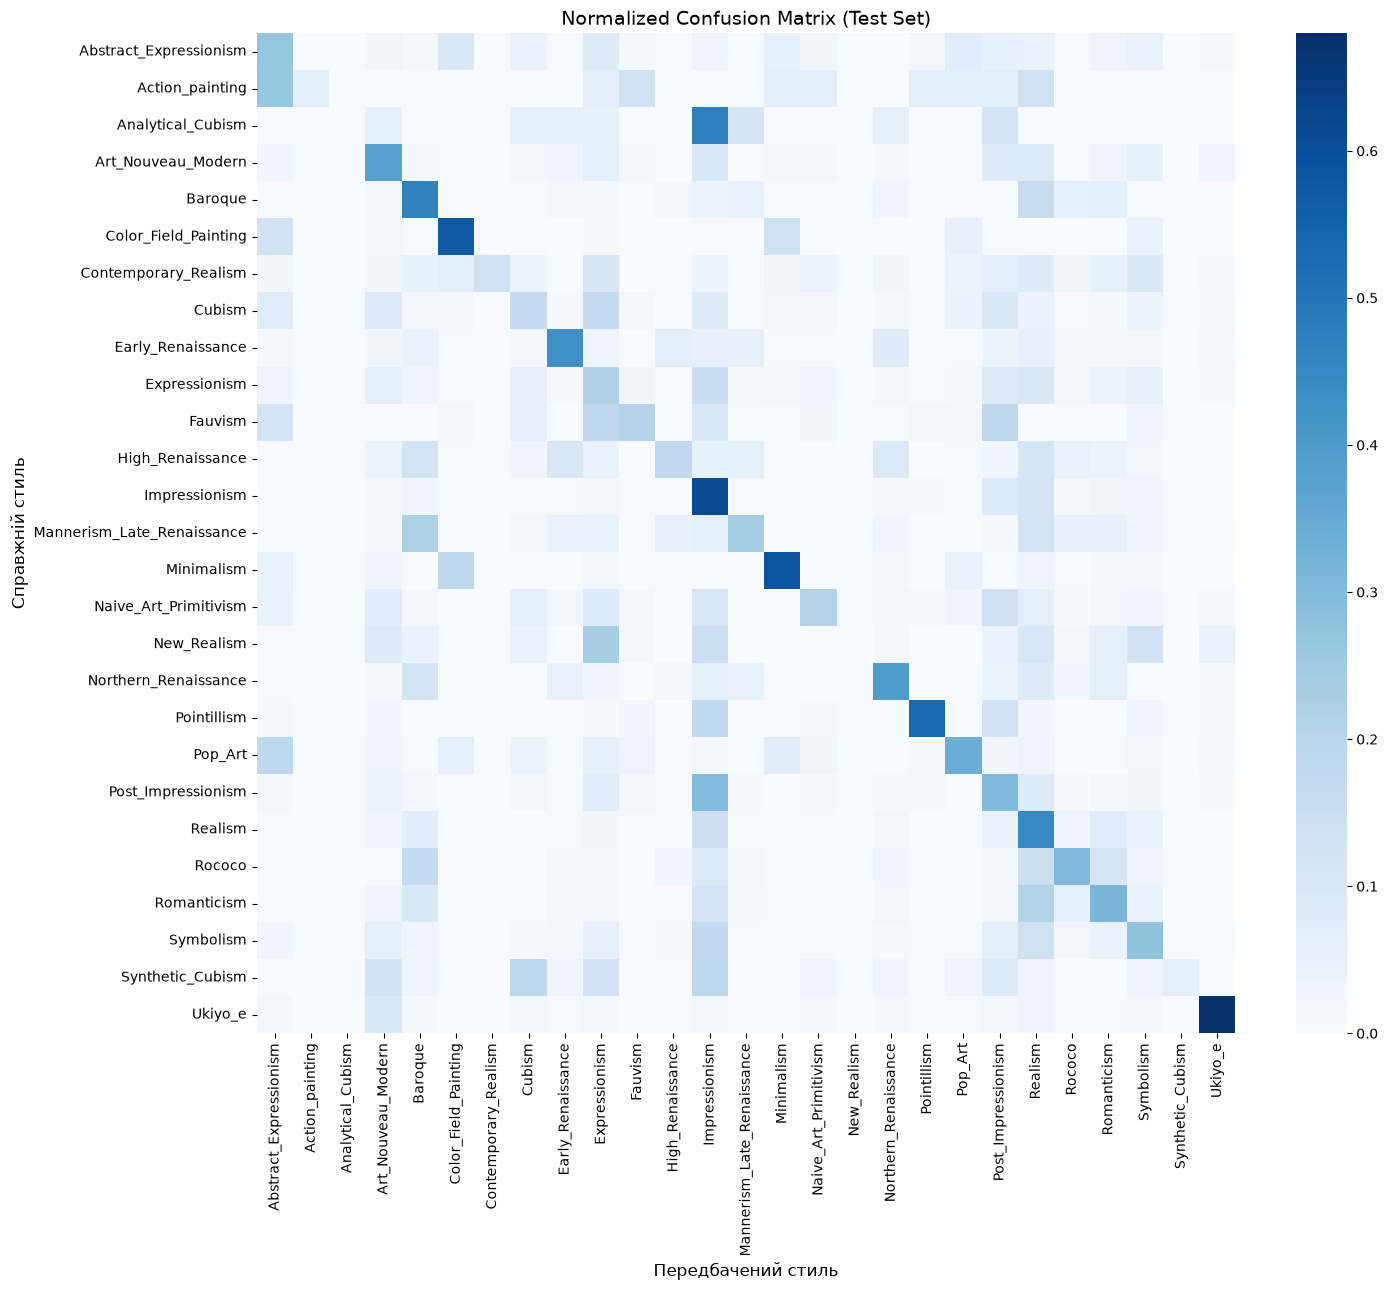


Classification report (Test):
                            precision    recall  f1-score   support

    Abstract_Expressionism       0.29      0.27      0.28       417
           Action_painting       1.00      0.07      0.12        15
         Analytical_Cubism       0.00      0.00      0.00        17
        Art_Nouveau_Modern       0.37      0.38      0.37       650
                   Baroque       0.35      0.47      0.40       636
      Color_Field_Painting       0.50      0.57      0.53       242
      Contemporary_Realism       0.77      0.14      0.24        72
                    Cubism       0.22      0.17      0.19       335
         Early_Renaissance       0.34      0.43      0.38       209
             Expressionism       0.30      0.21      0.25      1010
                   Fauvism       0.22      0.21      0.22       140
          High_Renaissance       0.27      0.18      0.22       201
             Impressionism       0.49      0.61      0.54      1959
Mannerism_Late_R

d:\AI_lab1\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\AI_lab1\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\AI_lab1\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [ ]:
p_gb_te = gbdt_tuned.predict_proba(X_te_full)
p_et_te = et_model.predict_proba(X_te_full)
p_final_test = best_w * p_gb_te + (1.0 - best_w) * p_et_te
y_pred_test = np.argmax(p_final_test, axis=1)

top1_test = accuracy_score(y_test, y_pred_test)
top3_test = top_k_accuracy_score(y_test, p_final_test, k=3)
f1_test = f1_score(y_test, y_pred_test, average='macro', zero_division=0)
bal_test = balanced_accuracy_score(y_test, y_pred_test)

print('Фінальні результати на Test:')
print(f'  Top-1 Accuracy:    {top1_test * 100:.2f}%')
print(f'  Top-3 Accuracy:    {top3_test * 100:.2f}%')
print(f'  Macro F1:          {f1_test:.4f}')
print(f'  Balanced Accuracy: {bal_test * 100:.2f}%\n')

cm = confusion_matrix(y_test, y_pred_test, normalize='true')

plt.figure(figsize=(15, 13))
sns.heatmap(
    cm,
    annot=False,
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)
plt.title('Normalized Confusion Matrix (Test Set)', fontsize=14)
plt.xlabel('Передбачений стиль', fontsize=12)
plt.ylabel('Справжній стиль', fontsize=12)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

print('\nClassification report (Test):')
print(classification_report(y_test, y_pred_test, target_names=classes))